# Part 1: Lower-Dimensional Representations of PBMCs

Compress 700 PBMC single-cell expression profiles (765 genes) and compare three 2-D views:

1. **PCA** on raw gene expression
2. **t-SNE** on raw gene expression (after a 50-component PCA)
3. **PCA of the latent space** of a PyTorch autoencoder (32-D bottleneck)

Run from the `notebooks/` directory. Data is read from `../data/`; figures are written to `../figures/`.

In [1]:
import os
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [2]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch version:", torch.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

DATA_DIR = "../data"
FIG_DIR = "../figures"
os.makedirs(FIG_DIR, exist_ok=True)

PyTorch version: 2.10.0+cpu
Using device: cpu


## 1. Load data

- `processed_counts.csv`: normalized log counts, one row per cell (10x barcode), one column per gene (765 genes).
- `labels.csv`: cell-type label per barcode, assigned by the original researchers (`bulk_labels`).

In [3]:
counts_pd = pd.read_csv(os.path.join(DATA_DIR, "processed_counts.csv"), index_col=0)
labels_pd  = pd.read_csv(os.path.join(DATA_DIR, "labels.csv"))

In [4]:
print("Counts shape :", counts_pd.shape)
print("Labels shape :", labels_pd.shape)

Counts shape : (700, 765)
Labels shape : (700, 2)


In [5]:
labels_pd = labels_pd.set_index("index")
labels_pd = labels_pd.loc[counts_pd.index]

X_all = counts_pd.values.astype(np.float32)
y_all = labels_pd["bulk_labels"].values

cell_types = sorted(list(set(y_all)))
print(f"\n{len(cell_types)} unique cell types:")
for ct in cell_types:
    print(f"  {ct}: {np.sum(y_all == ct)} cells")


10 unique cell types:
  CD14+ Monocyte: 129 cells
  CD19+ B: 95 cells
  CD34+: 13 cells
  CD4+/CD25 T Reg: 68 cells
  CD4+/CD45RA+/CD25- Naive T: 8 cells
  CD4+/CD45RO+ Memory: 19 cells
  CD56+ NK: 31 cells
  CD8+ Cytotoxic T: 54 cells
  CD8+/CD45RA+ Naive Cytotoxic: 43 cells
  Dendritic: 240 cells


## 2. Shuffle and split (80/20)

Features and labels are shuffled with the same permutation so they stay aligned.

In [6]:
N = X_all.shape[0]
perm = np.random.permutation(N)
X_shuffled = X_all[perm]
y_shuffled = y_all[perm]

n_train = int(0.8 * N)
X_train, X_test = X_shuffled[:n_train], X_shuffled[n_train:]
y_train, y_test = y_shuffled[:n_train], y_shuffled[n_train:]

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

X_train_t = torch.tensor(X_train).to(device)
X_test_t  = torch.tensor(X_test).to(device)
X_all_t   = torch.tensor(X_all).to(device)

Train: (560, 765), Test: (140, 765)


## 3. Autoencoder architecture

A fully connected autoencoder with a 32-dimensional latent space:

`765 → 128 → 64 → 32 (latent) → 64 → 128 → 765`, ReLU activations. The `Encoder` is a standalone
module so the latent representation can be extracted after training.

In [7]:
INPUT_DIM  = 765
LATENT_DIM = 32

class Encoder(nn.Module):

    def __init__(self, input_dim=INPUT_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, latent_dim),
        )

    def forward(self, x):
        return self.net(x)


class Decoder(nn.Module):

    def __init__(self, latent_dim=LATENT_DIM, output_dim=INPUT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, output_dim),
        )

    def forward(self, z):
        return self.net(z)


class Autoencoder(nn.Module):

    def __init__(self, input_dim=INPUT_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = Encoder(input_dim, latent_dim)
        self.decoder = Decoder(latent_dim, input_dim)

    def forward(self, x):
        z    = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat, z

model = Autoencoder().to(device)
sample_out, sample_z = model(X_train_t[:5])
print("Input  shape:", X_train_t[:5].shape)
print("Latent shape:", sample_z.shape)
print("Output shape:", sample_out.shape)

Input  shape: torch.Size([5, 765])
Latent shape: torch.Size([5, 32])
Output shape: torch.Size([5, 765])


## 4. Train with MSE reconstruction loss + L1 sparsity on the latent code

Adam (lr = 1e-4), batch size 64, 200 epochs, L1 weight 1e-5 on the latent activations.
Train and held-out test MSE are tracked every epoch to check that the model is not overfitting.

In [8]:
EPOCHS     = 200
LR         = 1e-4
BATCH_SIZE = 64
LAMBDA_L1  = 1e-5


def train_autoencoder(model, X_tr, X_te,
                      epochs=EPOCHS, lr=LR,
                      batch_size=BATCH_SIZE, lambda_l1=LAMBDA_L1):

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    mse_fn    = nn.MSELoss()

    train_losses, test_losses = [], []
    n_train = X_tr.shape[0]

    for epoch in range(epochs):
        model.train()
        idx = torch.randperm(n_train, device=device)
        epoch_loss = 0.0
        n_batches  = 0

        for start in range(0, n_train, batch_size):
            batch = X_tr[idx[start : start + batch_size]]

            x_hat, z = model(batch)

            mse_loss = mse_fn(x_hat, batch)

            l1_loss  = lambda_l1 * torch.mean(torch.abs(z))

            loss = mse_loss + l1_loss

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += mse_loss.item()
            n_batches  += 1

        model.eval()
        with torch.no_grad():
            tr_mse = mse_fn(model(X_tr)[0], X_tr).item()
            te_mse = mse_fn(model(X_te)[0], X_te).item()

        train_losses.append(tr_mse)
        test_losses.append(te_mse)

        if (epoch + 1) % 20 == 0:
            print(f"Epoch {epoch+1:>3}/{epochs}  |  "
                  f"Train MSE: {tr_mse:.4f}  |  Test MSE: {te_mse:.4f}")

    return train_losses, test_losses


model = Autoencoder().to(device)
train_losses, test_losses = train_autoencoder(
    model, X_train_t, X_test_t
)

print(f"\nFinal  Train MSE: {train_losses[-1]:.4f}")
print(f"Final  Test  MSE: {test_losses[-1]:.4f}")

Epoch  20/200  |  Train MSE: 0.9121  |  Test MSE: 1.0026
Epoch  40/200  |  Train MSE: 0.8476  |  Test MSE: 0.9445
Epoch  60/200  |  Train MSE: 0.8166  |  Test MSE: 0.9177
Epoch  80/200  |  Train MSE: 0.8004  |  Test MSE: 0.9089
Epoch 100/200  |  Train MSE: 0.7885  |  Test MSE: 0.9054
Epoch 120/200  |  Train MSE: 0.7772  |  Test MSE: 0.9035
Epoch 140/200  |  Train MSE: 0.7661  |  Test MSE: 0.9023
Epoch 160/200  |  Train MSE: 0.7553  |  Test MSE: 0.9018
Epoch 180/200  |  Train MSE: 0.7448  |  Test MSE: 0.9017
Epoch 200/200  |  Train MSE: 0.7345  |  Test MSE: 0.9019

Final  Train MSE: 0.7345
Final  Test  MSE: 0.9019


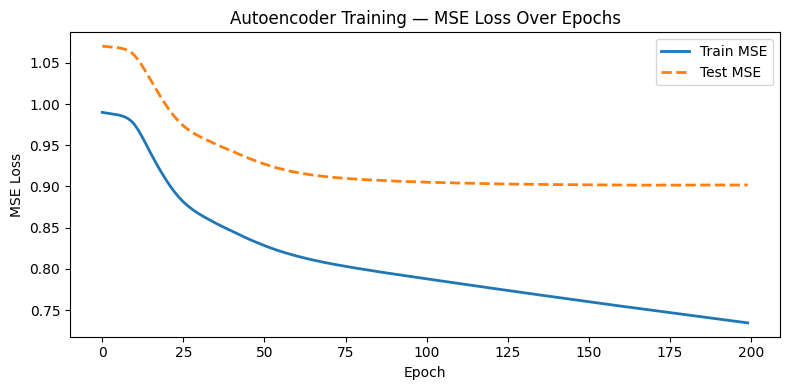

Saved: ../figures/loss_curves.png


In [9]:
plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Train MSE",  linewidth=2)
plt.plot(test_losses,  label="Test MSE",   linewidth=2, linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training — MSE Loss Over Epochs")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "loss_curves.png"), dpi=150)
plt.show()
print(f"Saved: {FIG_DIR}/loss_curves.png")

## 5. Retrain on all cells

The held-out curve plateaus around epoch 140 (test MSE ≈ 0.90) while training MSE keeps falling, so the
same architecture and hyperparameters are retrained on all 700 cells to produce the final embedding.
The autoencoder is unsupervised, so cell-type labels are never used in training.

In [10]:
model_full = Autoencoder().to(device)

optimizer_full = torch.optim.Adam(model_full.parameters(), lr=LR)
mse_fn = nn.MSELoss()

print("Retraining on full dataset...")
for epoch in range(EPOCHS):
    model_full.train()
    idx = torch.randperm(N, device=device)
    for start in range(0, N, BATCH_SIZE):
        batch = X_all_t[idx[start : start + BATCH_SIZE]]
        x_hat, z = model_full(batch)
        loss = mse_fn(x_hat, batch) + LAMBDA_L1 * torch.mean(torch.abs(z))
        optimizer_full.zero_grad()
        loss.backward()
        optimizer_full.step()

    if (epoch + 1) % 50 == 0:
        model_full.eval()
        with torch.no_grad():
            full_mse = mse_fn(model_full(X_all_t)[0], X_all_t).item()
        print(f"  Epoch {epoch+1}/{EPOCHS}  |  Full-data MSE: {full_mse:.4f}")

print("Done.")

Retraining on full dataset...
  Epoch 50/200  |  Full-data MSE: 0.8352
  Epoch 100/200  |  Full-data MSE: 0.7994
  Epoch 150/200  |  Full-data MSE: 0.7709
  Epoch 200/200  |  Full-data MSE: 0.7467
Done.


## 6. Compare 2-D embeddings

Cells are colored by their original cell-type label.

In [11]:
model_full.eval()
with torch.no_grad():
    Z_latent = model_full.encoder(X_all_t).cpu().numpy()

print("Latent representation shape:", Z_latent.shape)

Latent representation shape: (700, 32)


In [12]:
palette = sns.color_palette("tab10", n_colors=len(cell_types))
color_map = {ct: palette[i] for i, ct in enumerate(cell_types)}
colors = [color_map[ct] for ct in y_all]


def plot_embedding(coords_2d, labels, title, filename):
    fig, ax = plt.subplots(figsize=(9, 7))
    for ct in cell_types:
        mask = labels == ct
        ax.scatter(
            coords_2d[mask, 0], coords_2d[mask, 1],
            c=[color_map[ct]], label=ct, s=30, alpha=0.8, edgecolors="none"
        )
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left",
              fontsize=8, markerscale=1.5)
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {filename}")

PC1 explains 5.3%, PC2 explains 3.4%


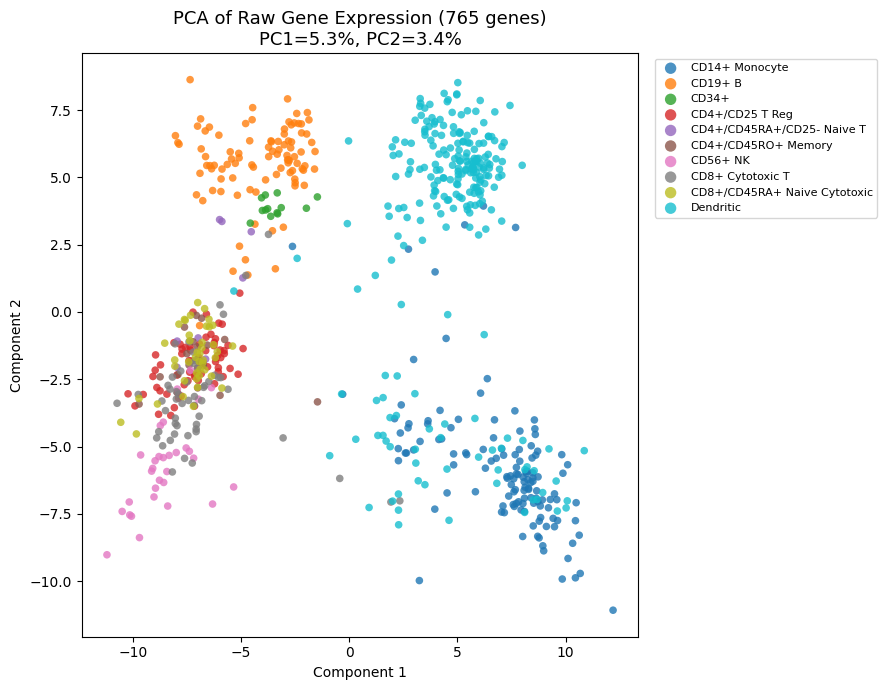

Saved: ../figures/plot_pca_raw.png


In [13]:
pca_raw = PCA(n_components=2, random_state=SEED)
X_pca   = pca_raw.fit_transform(X_all)
var_explained = pca_raw.explained_variance_ratio_
print(f"PC1 explains {var_explained[0]*100:.1f}%, PC2 explains {var_explained[1]*100:.1f}%")

plot_embedding(
    X_pca, y_all,
    title=f"PCA of Raw Gene Expression (765 genes)\n"
          f"PC1={var_explained[0]*100:.1f}%, PC2={var_explained[1]*100:.1f}%",
    filename=os.path.join(FIG_DIR, "plot_pca_raw.png")
)

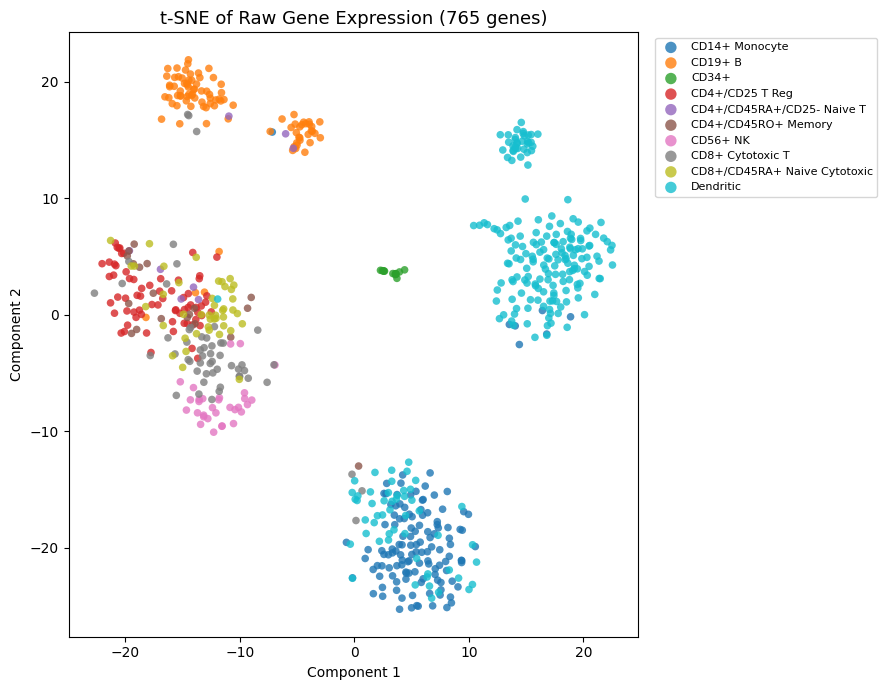

Saved: ../figures/plot_tsne_raw.png


In [14]:
pca50  = PCA(n_components=50, random_state=SEED)
X_pc50 = pca50.fit_transform(X_all)

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    max_iter=1000,
    random_state=SEED
)
X_tsne = tsne.fit_transform(X_pc50)

plot_embedding(
    X_tsne, y_all,
    title="t-SNE of Raw Gene Expression (765 genes)",
    filename=os.path.join(FIG_DIR, "plot_tsne_raw.png")
)

PC1 explains 37.9%, PC2 explains 14.9%


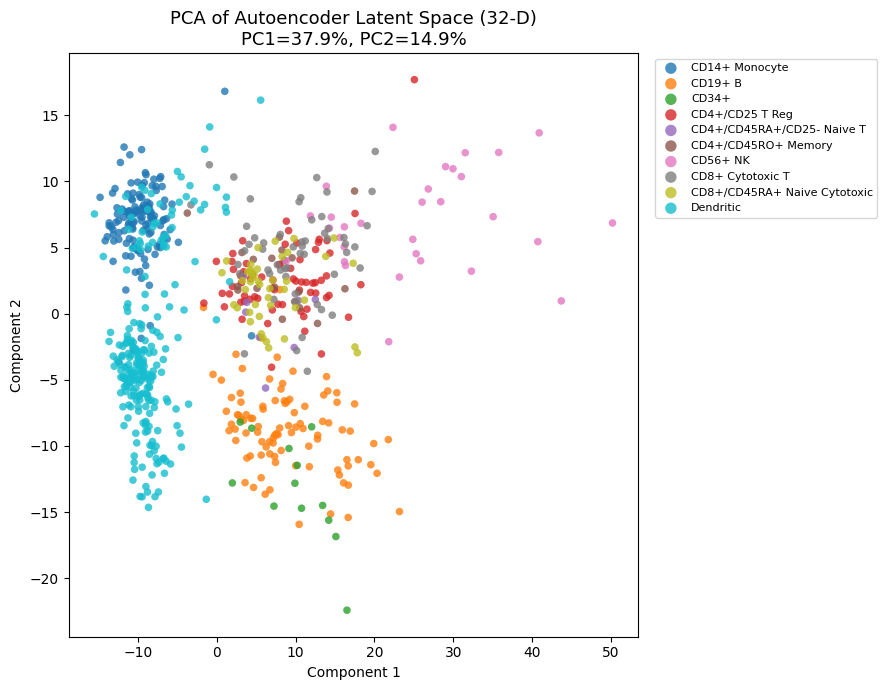

Saved: ../figures/plot_pca_latent.png


In [15]:
pca_latent = PCA(n_components=2, random_state=SEED)
Z_pca      = pca_latent.fit_transform(Z_latent)
var_lat    = pca_latent.explained_variance_ratio_
print(f"PC1 explains {var_lat[0]*100:.1f}%, PC2 explains {var_lat[1]*100:.1f}%")

plot_embedding(
    Z_pca, y_all,
    title=f"PCA of Autoencoder Latent Space (32-D)\n"
          f"PC1={var_lat[0]*100:.1f}%, PC2={var_lat[1]*100:.1f}%",
    filename=os.path.join(FIG_DIR, "plot_pca_latent.png")
)

## 7. Discussion

| Method | Input | Variance explained by 2 components |
|---|---|---|
| PCA | 765 raw genes | 8.7% |
| t-SNE | top 50 PCs of raw genes | n/a (non-linear) |
| PCA of latent space | 32-D autoencoder code | 52.8% (of the latent variance) |

- **t-SNE** gave the clearest separation of the ten populations. It preserves local neighborhoods, so B cells,
  CD34+ progenitors, dendritic cells, and monocytes form distinct islands, and even some related T-cell
  populations partially separate. Its limitation is that distances *between* clusters are not meaningful.
- **Raw PCA** is linear and captures little variance in two components, so the T-cell subtypes
  (CD4+, CD8+, regulatory, naive) overlap heavily.
- **Autoencoder latent PCA** is a middle ground: the non-linear bottleneck filters noise and yields a more
  structured space. Held-out reconstruction MSE of 0.90 shows the 32-D code retains most of the signal.
  The variance percentages are computed over different spaces (765-D vs. 32-D), so they describe how compact
  each representation is rather than which one separates cell types better. Because the final step is still
  linear, it does not resolve non-linear cluster boundaries as well as t-SNE.